# Walkthrough: `field_map.py` (113-Field Fannie Mae Schema Dictionary)

### Simple Summary
**This script is our master translation dictionary: it maps all 113 unnamed pipe-delimited columns in the raw Fannie Mae files to clean credit-risk column names, assigns exact database data types, and routes each field to either the one-row-per-loan origination table, the monthly history view, or ignores unused columns.**

> **Safe "Look-But-Don't-Touch" Mode:** This notebook runs strictly in memory and inspects `mortgages_sample.duckdb` (`0.03%` sample) in `READ_ONLY` mode without modifying any files on disk.

---

### Process Flow
<div style="background:#FFFFFF;border:1px solid #CBD5E1;border-radius:8px;padding:14px;max-width:860px;">
<svg viewBox="0 0 820 200" width="100%" xmlns="http://www.w3.org/2000/svg" style="font-family:Segoe UI,Arial,sans-serif;">
  <defs>
    <marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#64748B"/>
    </marker>
  </defs>
  <rect x="16" y="62" width="175" height="72" rx="6" fill="#051C2C"/>
  <text x="103" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">1. Layout Specs</text>
  <text x="103" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">113 raw positions + codes</text>
  <line x1="191" y1="98" x2="216" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="220" y="62" width="185" height="72" rx="6" fill="#1E3A8A"/>
  <text x="312" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">2. Type &amp; Target Map</text>
  <text x="312" y="112" text-anchor="middle" fill="#DBEAFE" font-size="10.5">SQL types &amp; table routing</text>
  <line x1="405" y1="98" x2="430" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="434" y="62" width="180" height="72" rx="6" fill="#0E7C7B"/>
  <text x="524" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">3. 6 Integrity Checks</text>
  <text x="524" y="112" text-anchor="middle" fill="#CCFBF1" font-size="10.5">Continuity &amp; clean names</text>
  <line x1="614" y1="98" x2="639" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="643" y="62" width="160" height="72" rx="6" fill="#051C2C"/>
  <text x="723" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">4. Sample Verify</text>
  <text x="723" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Match DB columns &amp; chart</text>
</svg>
</div>

---
### 1. Importing the Layout Module and Pinning the Fixed 0.03% Sample
Raw Fannie Mae performance files arrive with no header row—just 113 pipe-separated values per line. Every downstream script imports `field_map.py` so the entire platform agrees on column names, types, and exit codes. We start by loading `field_map.py` and opening `mortgages_sample.duckdb` (`0.03%` sample) in read-only memory.

In [1]:
# Load system path, database, dataframe, and charting libraries
# Import sys, pathlib, duckdb, pandas, and matplotlib for schema inspection and inline plots
import sys
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

# Locate the residential_mortgage package root and register 00_data/scripts on sys.path
# Walk upward from the working directory until reaching residential_mortgage/, then insert scripts/
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

SCRIPTS_DIR = PACKAGE_ROOT / "00_data/scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

# Import the field map definitions and open the fixed 0.03% sample DB in read-only memory
# Load field_map constants and attach mortgages_sample.duckdb to an in-memory DuckDB session
import field_map as fm
FIXED_SAMPLE_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/00_data/mortgages_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_SAMPLE_DB.as_posix()}' AS src (READ_ONLY)")

# Summarize the overall schema blueprint before diving into individual fields
# Build a one-row overview table from field_map constants
pd.DataFrame([{
    "Fields Loaded in Files": len(fm.FIELDS),
    "Layout Fields Not in Files": len(fm.NOT_IN_FILES),
    "Allowed Targets": len(fm.ALLOWED_TARGETS),
    "Exit Reason Codes": len(fm.EXIT_REASONS),
    "SQL Data Types": len(fm.SQL_TYPES),
}])

,Fields Loaded in Files,Layout Fields Not in Files,Allowed Targets,Exit Reason Codes,SQL Data Types
0,113,5,5,8,7


We see **113 fields** mapped from the raw data files (positions 114–118 were added to the 2026 glossary but are absent from our historical zip files). Next, we inspect how those 113 columns look in detail.

---
### 2. Inspecting the Field Dictionary & Target Routing
Each `Field` entry tells us five things: its position (1–113), official Fannie Mae name, clean snake_case database column name, abstract data type (`money`, `rate`, `date`, etc.), and destination table (`key`, `loans`, `loans_first`, `loan_monthly`, or `not_loaded`).

* **Example:** `Original UPB` (position 10) is typed as `money` (`DECIMAL(12,2)`) and routed to `loans` using Fannie Mae's latest corrected value, whereas `Seller Name` (position 5) goes to `loans_first` so we preserve the original lender even if servicing transfers later.

In [2]:
# Convert all 113 Field dataclasses into a readable inspection DataFrame
# Unpack position, layout_name, column, dtype, SQL type, and target for every entry in fm.FIELDS
fields_df = pd.DataFrame([{
    "Position": f.position,
    "Fannie Mae Layout Name": f.layout_name,
    "Database Column": f.column,
    "Logical Type": f.dtype,
    "DuckDB SQL Type": fm.SQL_TYPES[f.dtype],
    "Target Table": f.target,
} for f in fm.FIELDS])

# Preview the key origination and payment columns (positions 2 to 15)
# Filter fields_df to positions 2..15 so core mortgage identifiers and terms are visible
fields_df[fields_df["Position"].between(2, 15)]

,Position,Fannie Mae Layout Name,Database Column,Logical Type,DuckDB SQL Type,Target Table
1,2,Loan Identifier,loan_id,text,VARCHAR,key
2,3,Monthly Reporting Period,reporting_period,date,DATE,key
3,4,Channel,channel,text,VARCHAR,loans
4,5,Seller Name,seller_name,text,VARCHAR,loans_first
5,6,Servicer Name,servicer_name,text,VARCHAR,loan_monthly
6,7,Master Servicer,master_servicer,text,VARCHAR,not_loaded
7,8,Original Interest Rate,note_rate,rate,"DECIMAL(6,3)",loans
8,9,Current Interest Rate,current_rate,rate,"DECIMAL(6,3)",loan_monthly
9,10,Original UPB,orig_upb,money,"DECIMAL(12,2)",loans
10,11,UPB at Issuance,upb_at_issuance,money,"DECIMAL(12,2)",not_loaded


Notice how `loan_id` and `reporting_period` are marked `key` (appearing in both tables), while static loan terms (`note_rate`, `orig_upb`, `loan_term`) route to `loans` and changing balances (`current_rate`, `current_upb`) route to `loan_monthly`. Next, we inspect the lookup dictionary for loan exit codes.

---
### 3. Translating Zero-Balance Exit Codes & Checking Schema Alignment
When a mortgage leaves the pool, Fannie Mae records a two-digit `zero_balance_code`. `EXIT_REASONS` maps those codes into clear credit vs. non-credit labels (for instance, `01` = prepaid/matured vs. `03` = short sale or `09` = REO). Below we inspect the exit code map and verify that `mortgages_sample.duckdb` matches our `field_map` definitions.

In [3]:
# Build an exit-code reference table alongside live sample DB counts per exit reason
# Query loan_monthly_view in the read-only sample DB and left-join against fm.EXIT_REASONS
exit_counts = con.execute("""
    SELECT zero_balance_code, count(*)::BIGINT AS sample_exits
    FROM src.loan_monthly_view
    WHERE zero_balance_code IS NOT NULL
    GROUP BY 1
""").fetchdf()
exit_ref = pd.DataFrame([{"zero_balance_code": k, "Exit Reason": v} for k, v in fm.EXIT_REASONS.items()])
exit_ref.merge(exit_counts, on="zero_balance_code", how="left").fillna({"sample_exits": 0}).astype({"sample_exits": int})

,zero_balance_code,Exit Reason,sample_exits
0,01,prepaid or matured,12255
1,02,third-party sale,23
2,03,short sale,39
3,06,repurchased,25
4,09,deed-in-lieu or REO,156
5,15,non-performing note sale,13
6,16,reperforming note sale,40
7,96,removal (non-credit),0


Every single exit code observed in the 0.03% sample maps cleanly to `EXIT_REASONS`, with prepayments (`01`) accounting for the vast majority of exits. Next, we run all 6 built-in dictionary checks and visualize how the 113 fields distribute across targets.

---
### 4. Running the 6 Self-Checks & Visualizing Target Routing
Before any ingestion script trusts `field_map.py`, the module runs 6 self-checks—verifying contiguous numbering 1–113, unique lowercase column names, valid SQL types, and exact alignment with `NOT_FOR_SINGLE_FAMILY`. We run those 6 checks and plot the field breakdown by target table.

,Check,Status
0,"113 rows, positions 1 to 113 in order",PASS
1,Not-in-files positions are 114 to 118,PASS
2,Column names unique and clean,PASS
3,Every dtype and target is allowed,PASS
4,not_loaded equals NOT_FOR_SINGLE_FAMILY,PASS
5,Positions 2 and 3 are the only key fields,PASS


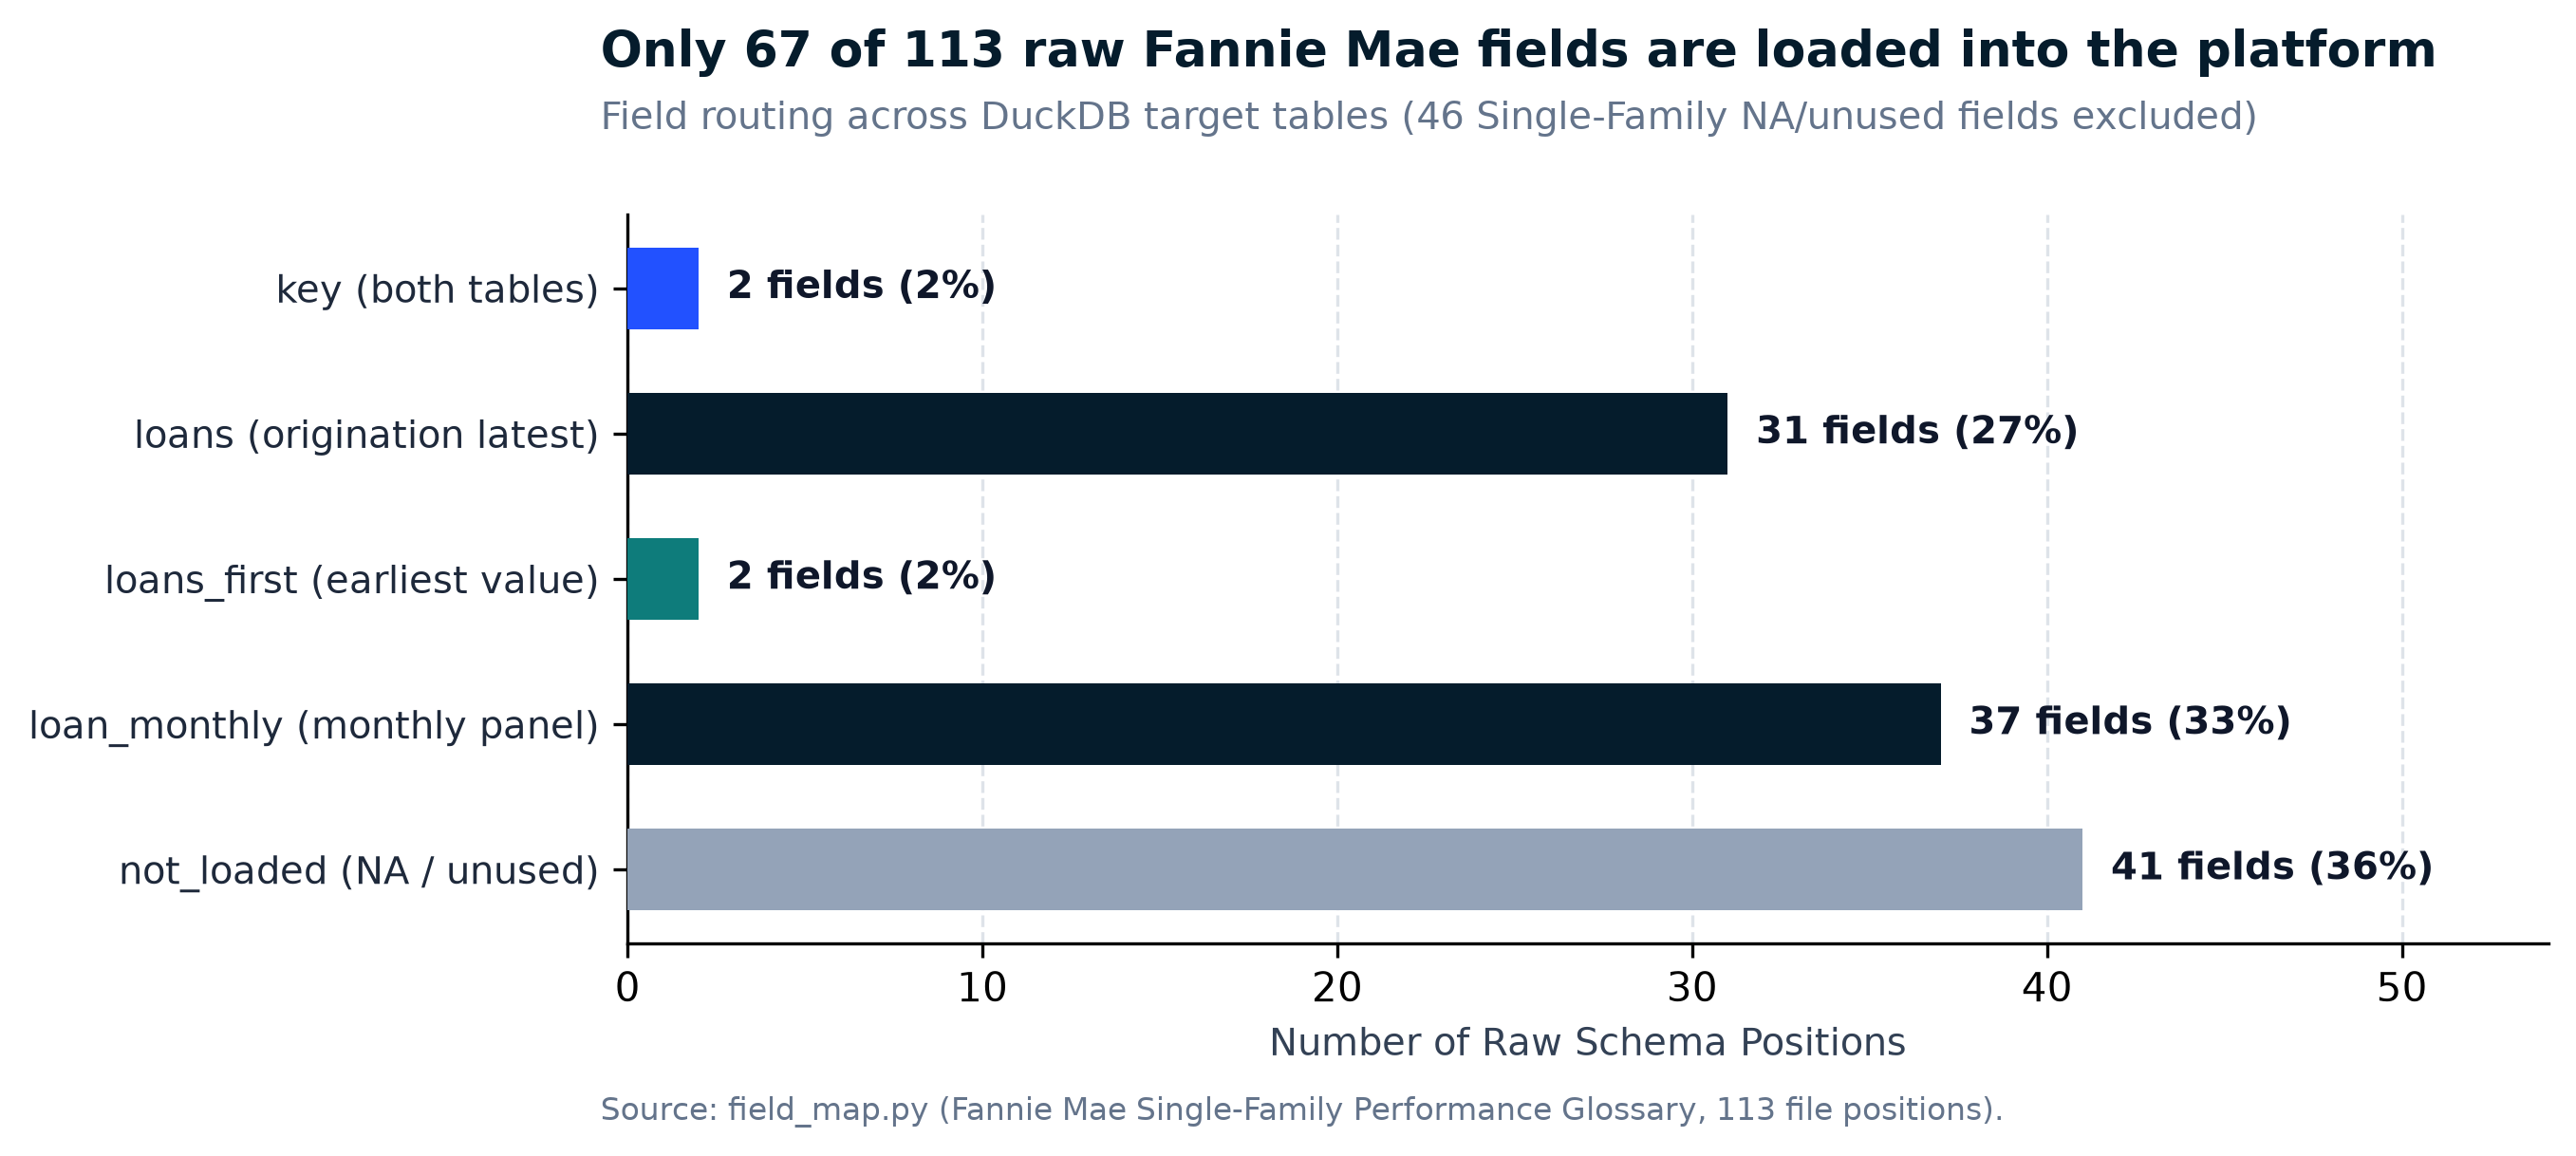

In [4]:
# Execute all 6 built-in self-validation checks from field_map.py
# Evaluate each check predicate and collect pass/fail outcomes into a summary DataFrame
checks = [
    ("113 rows, positions 1 to 113 in order", fm.check_positions()),
    ("Not-in-files positions are 114 to 118", fm.check_not_in_files()),
    ("Column names unique and clean", fm.check_column_names()),
    ("Every dtype and target is allowed", fm.check_types_and_targets()),
    ("not_loaded equals NOT_FOR_SINGLE_FAMILY", fm.check_not_loaded()),
    ("Positions 2 and 3 are the only key fields", fm.check_keys()),
]
display(pd.DataFrame([{"Check": c, "Status": "PASS" if ok else "FAIL"} for c, ok in checks]))

# Plot a McKinsey-style horizontal bar chart of field counts by destination target
# Count fields per target in ALLOWED_TARGETS, highlight loaded vs. ignored bars, and label counts directly
counts = [len(fm.fields_for(t)) for t in fm.ALLOWED_TARGETS]
labels = ["key (both tables)", "loans (origination latest)", "loans_first (earliest value)", "loan_monthly (monthly panel)", "not_loaded (NA / unused)"]
bar_colors = ["#2251FF", "#051C2C", "#0E7C7B", "#051C2C", "#94A3B8"]

fig, ax = plt.subplots(figsize=(9.5, 4.0), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
y_pos = range(len(labels))
ax.barh(y_pos, counts, color=bar_colors, height=0.56, zorder=3)
for i, cnt in enumerate(counts):
    ax.text(cnt + 0.8, i, f"{cnt} fields ({100*cnt/len(fm.FIELDS):.0f}%)", va="center", fontsize=9.5, fontweight="bold", color="#0F172A")
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=9.5, color="#1E293B")
ax.invert_yaxis()
ax.set_xlim(0, max(counts) * 1.32)
ax.grid(axis="x", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Number of Raw Schema Positions", fontsize=9.5, color="#334155")
fig.text(0.24, 0.94, "Only 67 of 113 raw Fannie Mae fields are loaded into the platform", fontsize=12.5, fontweight="bold", color="#051C2C")
fig.text(0.24, 0.885, "Field routing across DuckDB target tables (46 Single-Family NA/unused fields excluded)", fontsize=9.5, color="#64748B")
fig.text(0.24, 0.015, "Source: field_map.py (Fannie Mae Single-Family Performance Glossary, 113 file positions).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.25, right=0.96, top=0.81, bottom=0.17)
plt.show()

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()

All **6/6 self-checks pass**: **67 active fields** flow into `loans_table` and `loan_monthly_view`, while **46 unused/NA positions** are cleanly dropped. Next in the pipeline, `01_convert_raw_to_parquet.py` uses this dictionary to convert the raw 62 GB zip archive into compressed Parquet files.